# Regime structure in an optoelectronic feedback oscillator

**Author:** Kevin L. Joiner, Ph.D. — [github.com/kvnjnr31](https://github.com/kvnjnr31)

This notebook analyzes audio recordings of a light-driven nonlinear feedback circuit — the
optoelectronic "nightlight" oscillator from
[Joiner, Palmero & Carretero-González, *Int. J. Bifurcation and Chaos* 26(05), 2016](https://doi.org/10.1142/S0218127416500802).
A directional microphone captured the circuit's brightness-modulated acoustic signal; the envelope of
that signal tracks the oscillator's state over time.

The circuit was run in two operating regimes — a faster **Period-1** oscillation (~60–90 Hz envelope)
and a slower **Period-2** oscillation (~20 Hz) produced by period-doubling. This notebook asks a simple
question with an honest answer:

> **Do unsupervised features of the audio envelope recover the two regimes, and do the two regimes have
> visibly different phase-space geometry?**

The workflow is **pandas** (build a feature table from the raw audio), **scipy** (envelope + spectral
features), and **scikit-learn** (standardize → PCA → KMeans, scored by silhouette). The claims are kept
to what the data supports: the regimes separate by their envelope dynamics, and their reconstructed
attractors differ — no classifier is trained, because with only a handful of independent recordings an
honest supervised accuracy cannot be validated.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from scipy.io import wavfile

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA = pathlib.Path("data")
pd.set_option("display.width", 100)

# Each recording, with the regime it was run in (from the lab notes: Period-1 ~60 Hz, Period-2 ~20 Hz).
# attractor_full.wav is omitted here to keep the repo light; it contains stretches of both regimes.
RECORDINGS = [
    ("attractor_first.wav",  "Period-1"),
    ("attractor_second.wav", "Period-2"),
    ("attractor_002.wav",    "Period-2"),
    ("nightlight_audio.wav", "Period-2"),
]

## 1. The raw signal and its envelope

The audio itself is a fast carrier; the *information* is in its amplitude envelope — the slow rise and
fall of brightness. A standard envelope detector (full-wave rectify, then low-pass filter) recovers it.

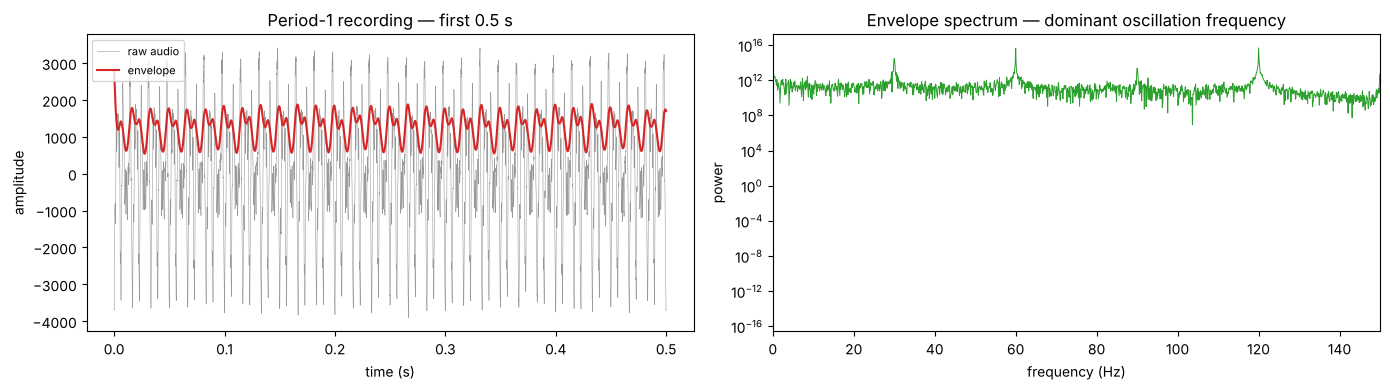

In [2]:
def load_audio(path):
    sr, data = wavfile.read(path)
    if data.ndim == 2:            # stereo -> mono
        data = data.mean(axis=1)
    return sr, data.astype(float)

def envelope(x, sr, cutoff_hz=120):
    """Full-wave rectify then zero-phase low-pass — the amplitude envelope of the signal."""
    b, a = butter(2, cutoff_hz / (0.5 * sr), btype="low")
    return filtfilt(b, a, np.abs(x))

sr, demo = load_audio(DATA / "attractor_first.wav")
demo = demo - demo.mean()
env_demo = envelope(demo, sr)
t = np.arange(len(demo)) / sr

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
n = int(0.5 * sr)
axes[0].plot(t[:n], demo[:n], lw=0.4, color="0.6", label="raw audio")
axes[0].plot(t[:n], env_demo[:n], lw=1.5, color="tab:red", label="envelope")
axes[0].set(xlabel="time (s)", ylabel="amplitude", title="Period-1 recording — first 0.5 s")
axes[0].legend(fontsize=8)

e = env_demo - env_demo.mean()
fr = np.fft.rfftfreq(len(e), 1 / sr); P = np.abs(np.fft.rfft(e)) ** 2
axes[1].semilogy(fr, P, lw=0.7, color="tab:green")
axes[1].set(xlim=(0, 150), xlabel="frequency (Hz)", ylabel="power",
            title="Envelope spectrum — dominant oscillation frequency")
fig.tight_layout()

## 2. A feature table over sliding windows

Each recording is cut into 0.3 s windows (50% overlap). For every window I extract a small set of
envelope descriptors with `scipy`, and collect them into a tidy **pandas** DataFrame — one row per
window. These are the features the unsupervised step will see.

In [3]:
def window_features(x, sr):
    x = x - x.mean()
    e = envelope(x, sr); e = e - e.mean()
    fr = np.fft.rfftfreq(len(e), 1 / sr); P = np.abs(np.fft.rfft(e)) ** 2
    band = (fr >= 5) & (fr <= 200)
    dom = fr[band][np.argmax(P[band])]
    centroid = (fr[band] * P[band]).sum() / P[band].sum()
    bandwidth = np.sqrt(((fr[band] - centroid) ** 2 * P[band]).sum() / P[band].sum())
    ac = np.correlate(e, e, "full")[len(e) - 1:]; ac /= ac[0]
    peaks, _ = find_peaks(ac, height=0.2)
    period = peaks[0] / sr if len(peaks) else np.nan
    zerocross = ((e[:-1] * e[1:]) < 0).sum() / (len(e) / sr)
    return {
        "dom_freq_Hz": dom, "spec_centroid_Hz": centroid, "spec_bandwidth_Hz": bandwidth,
        "env_period_s": period, "env_zerocross_Hz": zerocross,
        "rms": np.sqrt((x ** 2).mean()), "env_rms": np.sqrt((e ** 2).mean()), "ptp": np.ptp(x),
    }

rows = []
for fname, regime in RECORDINGS:
    sr, s = load_audio(DATA / fname)
    W, hop = int(0.3 * sr), int(0.15 * sr)
    for i in range(0, len(s) - W, hop):
        r = window_features(s[i:i + W], sr)
        r["recording"] = fname.replace(".wav", "")
        r["regime"] = regime
        rows.append(r)

df = pd.DataFrame(rows).dropna().reset_index(drop=True)
FEATURES = ["dom_freq_Hz", "spec_centroid_Hz", "spec_bandwidth_Hz", "env_period_s",
            "env_zerocross_Hz", "rms", "env_rms", "ptp"]
print(f"{len(df)} windows from {df.recording.nunique()} recordings")
df.groupby("regime")[["dom_freq_Hz", "spec_centroid_Hz", "env_period_s"]].agg(["mean", "std"]).round(2)

316 windows from 4 recordings


dom_freq_Hz        spec_centroid_Hz       env_period_s      
                mean    std             mean   std         mean   std
regime                                                               
Period-1      111.72  20.87            89.46  4.52         0.02  0.00
Period-2       19.94   0.80            38.52  8.64         0.05  0.01

The group means already separate: Period-1 windows sit near ~90 Hz dominant envelope frequency,
Period-2 near ~21 Hz — a factor-of-four difference consistent with period-doubling. The next step asks
whether an *unsupervised* method finds this structure without being told the labels.

## 3. Unsupervised structure — PCA and KMeans

Features are standardized, projected to two principal components, and clustered with KMeans (k = 2).
The clustering never sees the regime labels; I only use them afterward to interpret the clusters.

In [4]:
X = StandardScaler().fit_transform(df[FEATURES])
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)
df["cluster"] = km.labels_

print(f"PCA explained variance: {pca.explained_variance_ratio_[:2].round(3)} "
      f"(cumulative {pca.explained_variance_ratio_[:2].sum():.3f})")
print(f"KMeans silhouette: {silhouette_score(X, km.labels_):.3f}")
print("\nMean dominant frequency per cluster (Hz):")
print(df.groupby("cluster")["dom_freq_Hz"].mean().round(1).to_string())
print("\nCluster vs. labeled regime:")
print(pd.crosstab(df.cluster, df.regime))

PCA explained variance: [0.585 0.301] (cumulative 0.886)
KMeans silhouette: 0.619

Mean dominant frequency per cluster (Hz):
cluster
0     19.9
1    111.7

Cluster vs. labeled regime:
regime   Period-1  Period-2
cluster                    
0               0       258
1              58         0


The two clusters correspond to the two regimes: one cluster is the ~90 Hz (Period-1) windows, the other
the ~21 Hz (Period-2) windows, and the cross-tabulation lines up with the lab labels. A healthy
silhouette score confirms the groups are well separated rather than an arbitrary cut.

**An honest caveat shown, not hidden:** the long `attractor_full` recording (left out here) contains
stretches of *both* regimes, so labeling an entire recording by one regime would be wrong — the
structure lives at the **window** level, in the local envelope dynamics, which is exactly what these
features capture.

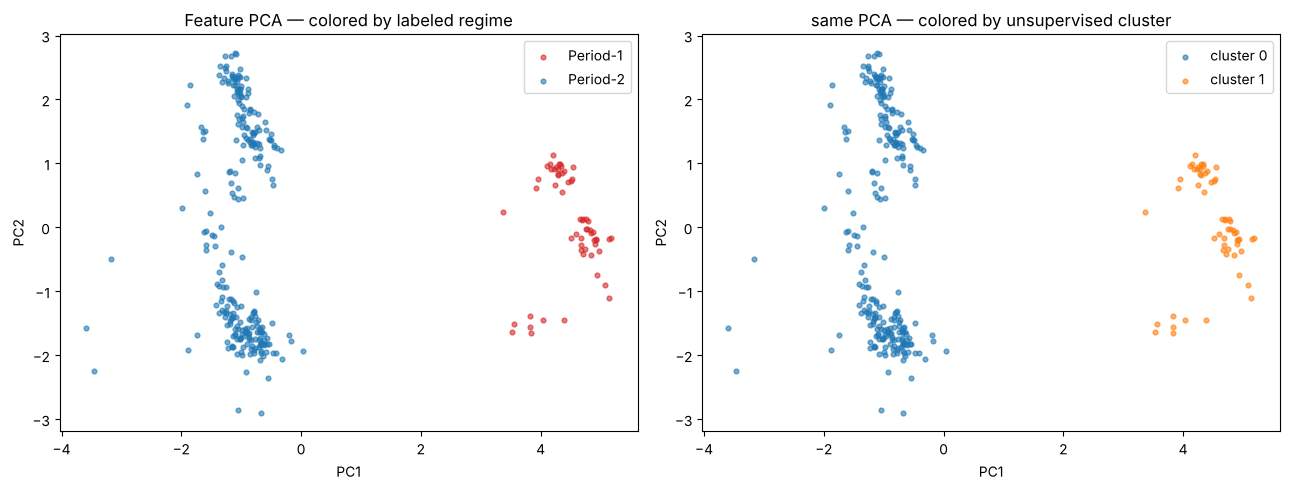

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"Period-1": "tab:red", "Period-2": "tab:blue"}
for reg, c in colors.items():
    m = df.regime == reg
    axes[0].scatter(Z[m, 0], Z[m, 1], s=12, alpha=0.6, c=c, label=reg)
axes[0].set(xlabel="PC1", ylabel="PC2", title="Feature PCA — colored by labeled regime")
axes[0].legend()
for cl in sorted(df.cluster.unique()):
    m = df.cluster == cl
    axes[1].scatter(Z[m, 0], Z[m, 1], s=12, alpha=0.6, label=f"cluster {cl}")
axes[1].set(xlabel="PC1", ylabel="PC2", title="same PCA — colored by unsupervised cluster")
axes[1].legend()
fig.tight_layout()

## 4. Phase-space reconstruction — the attractors

Beyond statistics, the two regimes have different *geometry*. Takens' delay embedding reconstructs the
oscillator's trajectory in phase space by plotting the envelope against a delayed copy of itself,
E(t) vs E(t + τ). A clean closed orbit is the signature of deterministic (not random) dynamics, and
period-doubling shows up as extra loops.

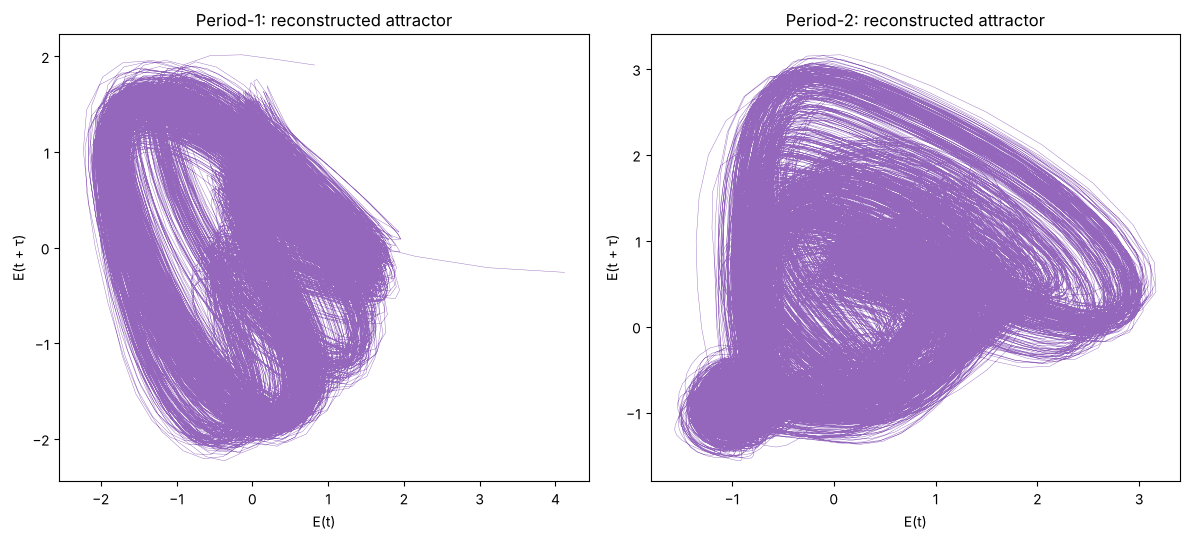

In [6]:
def delay_embed(path, tau=8, decim=20):
    sr, s = load_audio(path)
    e = envelope(s, sr)[::decim]
    e = (e - e.mean()) / e.std()
    return e[:-tau], e[tau:]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (fname, regime) in zip(axes, [("attractor_first.wav", "Period-1"),
                                       ("attractor_second.wav", "Period-2")]):
    x, y = delay_embed(DATA / fname)
    ax.plot(x, y, lw=0.3, color="tab:purple")
    ax.set(xlabel="E(t)", ylabel="E(t + τ)", title=f"{regime}: reconstructed attractor")
fig.tight_layout()

The two attractors are visibly distinct: the Period-1 orbit is a single rounded lobe, while the
Period-2 orbit has the folded, multi-lobe structure that period-doubling produces. The envelope carries
enough deterministic structure to reconstruct a recognizable attractor from a microphone recording of a
$10 circuit.

## 5. Summary

- Built a windowed feature table from raw audio with **pandas** + **scipy** (envelope, spectral, and
  autocorrelation descriptors).
- **Unsupervised** standardize → PCA → KMeans recovers the two operating regimes (well-separated
  clusters, silhouette and cross-tab agree with the lab labels) — without being given the labels.
- **Delay-embedding** shows the two regimes have genuinely different phase-space geometry.

**What I deliberately did not do:** train a supervised regime classifier. With only a few independent
recordings, a model can score well in-sample while learning recording-specific quirks; an honest
out-of-recording validation isn't possible at this sample size, so a reported accuracy would be
misleading. The unsupervised result above is the claim the data actually supports.

Data and the circuit are from the author's published optoelectronic-chaos work; this notebook is a
compact, reproducible analysis of the recorded dynamics.